# Student Performance EDA
**Engagement 1 — County Education Office**

**Dataset:** `student_performance.csv` · 1,200 students · seed 55  
**Purpose:** Identify learners most at risk of poor performance and factors associated with better results to inform a county learner-support programme budget proposal.

---
### EDA Framework
This notebook follows five structured steps:  
1. **Structure** — grain, schema, data quality  
2. **Univariate** — distributions of individual variables  
3. **Bivariate** — pairwise relationships  
4. **Multivariate** — interactions across three or more dimensions  
5. **Hypotheses** — trend line, school-type gap, formal tests  


### Results at a glance
| Question | Answer |
|---|---|
| Strongest link with average_score | study_hours (r = 0.70); attendance_rate r = 0.36 |
| Trend line | +2.12 points per extra study hour, R² = 0.50 (Section 5) |
| School-type gap | Private +5.6 points; holds in every attendance band and study quartile (Section 4) |
| Highest At Risk county | Nairobi 9.2%, not significantly different from the rest (chi-square p = 0.92) |
| Who is At Risk | 95% in public schools; lowest study quartile is 21% At Risk (Section 4) |

Findings, Recommendations and Limitations are the last section of this notebook.

---
## 0 · Setup — Imports and Global Settings

In [1]:
import os
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
from scipy import stats

warnings.filterwarnings("ignore")
os.makedirs("figures", exist_ok=True)

# Consistent style across all charts in this notebook
plt.rcParams.update({
    "figure.dpi": 80,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.titlesize": 11,
    "axes.titleweight": "bold",
    "axes.labelsize": 9,
    "xtick.labelsize": 8,
    "ytick.labelsize": 8,
})

print("Libraries loaded.")
print(f"  pandas  {pd.__version__}")
print(f"  numpy   {np.__version__}")

Libraries loaded.
  pandas  3.1.1
  numpy   2.5.5


---
## 1 · Structure
**Goal:** Understand the grain of the data, the variables and their types, and confirm there are no data-quality issues before any analysis begins.

In [2]:
# Load dataset
df = pd.read_csv("student_performance.csv")

print("=" * 55)
print("DATASET OVERVIEW")
print("=" * 55)
print(f"Rows : {df.shape[0]:,}")
print(f"Cols : {df.shape[1]}")
print()
print(df.dtypes)
print()
df.head()

DATASET OVERVIEW
Rows : 1,200
Cols : 9

student_id           int64
county                 str
school_type            str
gender                 str
attendance_rate    float64
study_hours        float64
math               float64
english            float64
science            float64
dtype: object



,student_id,county,school_type,gender,attendance_rate,study_hours,math,english,science
0,1,Turkana,Private,M,0.77,6.5,81.0,71.0,73.0
1,2,Nyeri,Private,M,0.97,8.5,100.0,86.0,90.0
2,3,Nyeri,Private,F,0.98,8.0,82.0,89.0,90.0
3,4,Turkana,Public,M,0.93,6.0,83.0,91.0,72.0
4,5,Kisumu,Private,F,0.67,6.1,76.0,69.0,62.0


In [3]:
# Grain check: each row should be one unique student
n_unique_ids = df["student_id"].nunique()
print(f"Unique student_ids : {n_unique_ids}  (expected {len(df)})")
print(f"Duplicate rows     : {df.duplicated().sum()}")

# Missing values
print("\nMissing values per column:")
print(df.isnull().sum())

# Value ranges for key numeric columns
print("\nValue ranges:")
for col in ["attendance_rate", "study_hours", "math", "english", "science"]:
    print(f"  {col:<18} min={df[col].min():.2f}  max={df[col].max():.2f}")

Unique student_ids : 1200  (expected 1200)
Duplicate rows     : 0

Missing values per column:
student_id         0
county             0
school_type        0
gender             0
attendance_rate    0
study_hours        0
math               0
english            0
science            0
dtype: int64

Value ranges:
  attendance_rate    min=0.33  max=1.00
  study_hours        min=0.20  max=23.30
  math               min=37.00  max=100.00
  english            min=47.00  max=100.00
  science            min=35.00  max=100.00


In [4]:
# Categorical cardinalities
for col in ["county", "school_type", "gender"]:
    print(f"\n{col} ({df[col].nunique()} unique values):")
    print(df[col].value_counts(normalize=True).mul(100).round(1).to_string())


county (6 unique values):
county
Mombasa    17.7
Kisumu     17.3
Nyeri      16.9
Nakuru     16.8
Turkana    15.9
Nairobi    15.3

school_type (2 unique values):
school_type
Public     72.2
Private    27.8

gender (2 unique values):
gender
F    51.0
M    49.0


### Structure — Summary

| Attribute | Detail |
|-----------|--------|
| **Grain** | One row = one student |
| **Rows** | 1,200 |
| **Columns** | 9 (student_id, county, school_type, gender, attendance_rate, study_hours, math, english, science) |
| **Missing values** | None |
| **Duplicate rows** | None |
| **Score range** | 0–100 (clipped by design) |

**Data quality verdict:** The dataset is clean — no missing values, no duplicate IDs, and all numeric values fall within their expected ranges.

---
## 2 · Univariate
**Goal:** Summarise every numerical variable (centre, spread, shape) and every categorical variable (counts and shares). Identify outliers in `study_hours`.

We first create two derived columns that will be used throughout the notebook:
- `average_score` — arithmetic mean of `math`, `english`, `science`
- `performance_band` — ordinal bin using `pd.cut`

In [5]:
# ── Derived columns ───────────────────────────────────────────────────────────
df["average_score"] = df[["math", "english", "science"]].mean(axis=1).round(2)

df["performance_band"] = pd.cut(
    df["average_score"],
    bins=[0, 60, 75, 101],
    labels=["At Risk", "Meeting", "Exceeding"],
    right=False          # [0,60) [60,75) [75,101)
)

print("Columns added:")
print(df[["average_score", "performance_band"]].head(10).to_string(index=False))

Columns added:
 average_score performance_band
         75.00        Exceeding
         92.00        Exceeding
         87.00        Exceeding
         82.00        Exceeding
         69.00          Meeting
         87.67        Exceeding
         59.67          At Risk
         92.33        Exceeding
         67.33          Meeting
         72.67          Meeting


In [6]:
# ── Numerical summary statistics ─────────────────────────────────────────────
num_cols = ["attendance_rate", "study_hours", "math", "english", "science", "average_score"]

summary = df[num_cols].agg(["mean", "median", "std", "min", "max",
                             lambda x: x.skew()]).T
summary.columns = ["Mean", "Median", "Std Dev", "Min", "Max", "Skewness"]
summary = summary.round(3)
print("Numerical Summaries")
print("=" * 60)
print(summary.to_string())

Numerical Summaries
                   Mean  Median  Std Dev    Min    Max  Skewness
attendance_rate   0.804    0.82    0.119   0.33    1.0    -0.858
study_hours       5.078    4.50    3.028   0.20   23.3     1.174
math             71.889   72.00   10.858  37.00  100.0     0.102
english          74.521   74.00   10.487  47.00  100.0     0.160
science          69.612   69.00   12.022  35.00  100.0     0.107
average_score    72.007   71.67    9.106  48.33  100.0     0.262


In [7]:
# ── Categorical summaries ─────────────────────────────────────────────────────
print("Categorical Variable Summaries")
print("=" * 45)
for col in ["gender", "school_type", "county", "performance_band"]:
    counts = df[col].value_counts()
    shares = df[col].value_counts(normalize=True).mul(100).round(1)
    result = pd.DataFrame({"Count": counts, "Share (%)": shares})
    print(f"\n{col.upper()}")
    print(result.to_string())

Categorical Variable Summaries

GENDER
        Count  Share (%)
gender                  
F         612       51.0
M         588       49.0

SCHOOL_TYPE
             Count  Share (%)
school_type                  
Public         866       72.2
Private        334       27.8

COUNTY
         Count  Share (%)
county                   
Mombasa    212       17.7
Kisumu     208       17.3
Nyeri      203       16.9
Nakuru     202       16.8
Turkana    191       15.9
Nairobi    184       15.3

PERFORMANCE_BAND
                  Count  Share (%)
performance_band                  
Meeting             672       56.0
Exceeding           429       35.8
At Risk              99        8.2


In [8]:
# ── Outlier detection: study_hours using IQR method ──────────────────────────
Q1 = df["study_hours"].quantile(0.25)
Q3 = df["study_hours"].quantile(0.75)
IQR = Q3 - Q1
lower_fence = Q1 - 1.5 * IQR
upper_fence = Q3 + 1.5 * IQR

outliers = df[(df["study_hours"] < lower_fence) | (df["study_hours"] > upper_fence)]
print(f"study_hours outlier analysis (IQR method)")
print(f"  Q1 = {Q1:.2f}  |  Q3 = {Q3:.2f}  |  IQR = {IQR:.2f}")
print(f"  Lower fence = {lower_fence:.2f}  |  Upper fence = {upper_fence:.2f}")
print(f"  Outliers identified: {len(outliers)} ({len(outliers)/len(df)*100:.1f}% of students)")
print(f"  Max study hours overall: {df['study_hours'].max():.1f} h")

study_hours outlier analysis (IQR method)
  Q1 = 2.90  |  Q3 = 6.70  |  IQR = 3.80
  Lower fence = -2.80  |  Upper fence = 12.40
  Outliers identified: 29 (2.4% of students)
  Max study hours overall: 23.3 h


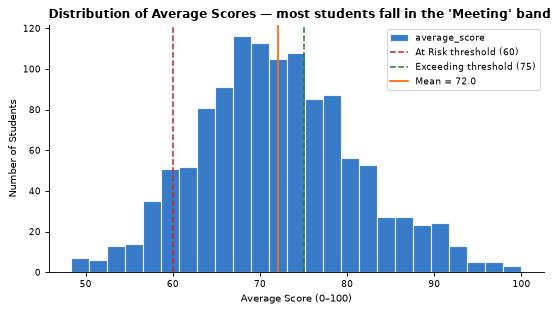

Saved → figures/score_hist.png


In [9]:
# ── Chart 1: Histogram of average_score ──────────────────────────────────────
fig, ax = plt.subplots(figsize=(7, 4))

df["average_score"].plot(
    kind="hist", bins=25, color="#1565C0", edgecolor="white",
    ax=ax, alpha=0.85
)

# Reference lines
ax.axvline(60, color="#C62828", linestyle="--", linewidth=1.4,
           label="At Risk threshold (60)")
ax.axvline(75, color="#2E7D32", linestyle="--", linewidth=1.4,
           label="Exceeding threshold (75)")
ax.axvline(df["average_score"].mean(), color="#FF6F00", linestyle="-",
           linewidth=1.6, label=f"Mean = {df['average_score'].mean():.1f}")

ax.set_title("Distribution of Average Scores — most students fall in the 'Meeting' band",
             loc="left")
ax.set_xlabel("Average Score (0–100)")
ax.set_ylabel("Number of Students")
ax.legend(fontsize=8)

plt.tight_layout()
plt.savefig("figures/score_hist.png", dpi=150, bbox_inches="tight")
plt.show()
print("Saved → figures/score_hist.png")

---
## 3 · Bivariate
**Goal:** Calculate correlations between all numerical variables and interpret the three strongest relationships with `average_score`. Compare scores by gender, school type and county.

In [10]:
# ── Correlation matrix ────────────────────────────────────────────────────────
num_cols_ext = ["attendance_rate", "study_hours", "math",
                "english", "science", "average_score"]
corr_matrix = df[num_cols_ext].corr().round(3)

print("Pearson Correlation Matrix")
print("=" * 55)
print(corr_matrix.to_string())

Pearson Correlation Matrix
                 attendance_rate  study_hours   math  english  science  average_score
attendance_rate            1.000       -0.029  0.300    0.327    0.260          0.359
study_hours               -0.029        1.000  0.560    0.624    0.550          0.704
math                       0.300        0.560  1.000    0.559    0.459          0.814
english                    0.327        0.624  0.559    1.000    0.502          0.827
science                    0.260        0.550  0.459    0.502    1.000          0.815
average_score              0.359        0.704  0.814    0.827    0.815          1.000


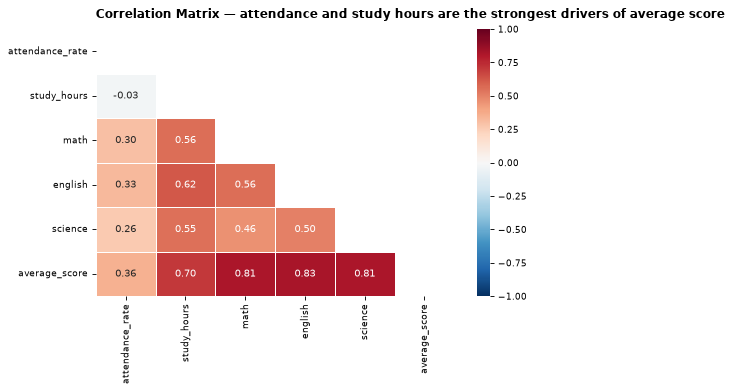

In [11]:
# ── Heatmap visualisation ─────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(7, 5))

mask = np.triu(np.ones_like(corr_matrix, dtype=bool))   # upper triangle
sns.heatmap(
    corr_matrix, mask=mask,
    annot=True, fmt=".2f", cmap="RdBu_r",
    center=0, vmin=-1, vmax=1,
    linewidths=0.5, ax=ax,
    annot_kws={"size": 9}
)
ax.set_title("Correlation Matrix — attendance and study hours are the strongest drivers of average score",
             loc="left", pad=10)

plt.tight_layout()
plt.show()

In [12]:
corr_avg = corr_matrix["average_score"].drop("average_score").sort_values(key=abs, ascending=False)

print("THREE STRONGEST correlations with average_score")
for rank, (col, r) in enumerate(corr_avg.head(3).items(), start=1):
    print(f"  {rank}. {col:<8} r = {r:+.3f}")
print("  -> All three are the subject scores that average_score is built from, so they are high by construction.\n")

def strength(r):
    r = abs(r)
    return "strong" if r >= 0.7 else "moderate" if r >= 0.4 else "weak-to-moderate" if r >= 0.2 else "weak"

print("STRONGEST INDEPENDENT factors (what a programme can act on)")
for col in ["study_hours", "attendance_rate"]:
    r = corr_avg[col]
    print(f"  {col:<16} r = {r:+.3f}  ({strength(r)} positive link; explains about {r**2*100:.0f}% of the variation in average_score)")

THREE STRONGEST correlations with average_score
  1. english  r = +0.827
  2. science  r = +0.815
  3. math     r = +0.814
  -> All three are the subject scores that average_score is built from, so they are high by construction.

STRONGEST INDEPENDENT factors (what a programme can act on)
  study_hours      r = +0.704  (strong positive link; explains about 50% of the variation in average_score)
  attendance_rate  r = +0.359  (weak-to-moderate positive link; explains about 13% of the variation in average_score)


### Interpretation: the three strongest correlations with `average_score`
The three strongest are **english (r = 0.827), science (r = 0.815) and math (r = 0.814)**. They are the components of `average_score`, so the link is built in and tells the programme nothing new.

Of the factors a programme could act on:
- **study_hours (r = 0.704, strong):** learners who study more score higher; study hours alone go with about half the variation in scores.
- **attendance_rate (r = 0.359, weak-to-moderate):** higher attendance goes with higher scores, but accounts for only about 13% of the variation.

*Correlation shows association only. It does not show that more study or attendance causes higher scores.*

In [13]:
# ── Average score by gender ───────────────────────────────────────────────────
gender_means = df.groupby("gender")["average_score"].mean().round(2)
print("Average score by Gender:")
print(gender_means.to_string())
print()

# ── Average score by school type ──────────────────────────────────────────────
school_means = df.groupby("school_type")["average_score"].mean().round(2)
print("Average score by School Type:")
print(school_means.to_string())
print()

# ── Average score by county ───────────────────────────────────────────────────
county_means = df.groupby("county")["average_score"].mean().sort_values().round(2)
print("Average score by County:")
print(county_means.to_string())

Average score by Gender:
gender
F    72.10
M    71.91

Average score by School Type:
school_type
Private    76.01
Public     70.46

Average score by County:
county
Turkana    70.97
Nakuru     71.84
Nyeri      71.94
Nairobi    71.96
Mombasa    72.17
Kisumu     73.07


In [14]:
# ── Which county has the highest share of At Risk learners? ───────────────────
at_risk_by_county = (
    df[df["performance_band"] == "At Risk"]
    .groupby("county").size()
    .div(df.groupby("county").size())
    .mul(100)
    .sort_values(ascending=False)
    .round(1)
)
print("Share of 'At Risk' learners by County (%):")
print(at_risk_by_county.to_string())
print()
print(f"→ County with the HIGHEST At Risk share: {at_risk_by_county.idxmax()} "
      f"({at_risk_by_county.max():.1f}%)")

Share of 'At Risk' learners by County (%):
county
Nairobi    9.2
Mombasa    9.0
Nyeri      8.9
Kisumu     8.2
Turkana    7.9
Nakuru     6.4

→ County with the HIGHEST At Risk share: Nairobi (9.2%)


In [15]:
ct = pd.crosstab(df["county"], df["performance_band"] == "At Risk")
chi2, p_chi, dof, _ = stats.chi2_contingency(ct)
print(f"Chi-square test, county x At Risk status: chi2 = {chi2:.2f}, dof = {dof}, p = {p_chi:.3f}")
print("p > 0.05 -> the differences between counties are within what chance alone could produce.")

Chi-square test, county x At Risk status: chi2 = 1.40, dof = 5, p = 0.924
p > 0.05 -> the differences between counties are within what chance alone could produce.


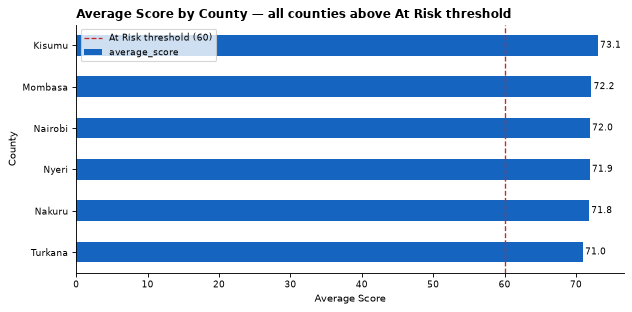

Saved → figures/county_bar.png


In [16]:
# ── Chart 2: Average score by county (bar chart) ──────────────────────────────
fig, ax = plt.subplots(figsize=(8, 4))

county_means.plot(
    kind="barh", color="#1565C0", edgecolor="none", ax=ax
)

ax.axvline(60, color="#C62828", linestyle="--", linewidth=1.2,
           label="At Risk threshold (60)")
ax.set_title("Average Score by County — all counties above At Risk threshold",
             loc="left")
ax.set_xlabel("Average Score")
ax.set_ylabel("County")
ax.legend(fontsize=8)

for i, (county, val) in enumerate(county_means.items()):
    ax.text(val + 0.3, i, f"{val:.1f}", va="center", fontsize=8)

plt.tight_layout()
plt.savefig("figures/county_bar.png", dpi=150, bbox_inches="tight")
plt.show()
print("Saved → figures/county_bar.png")

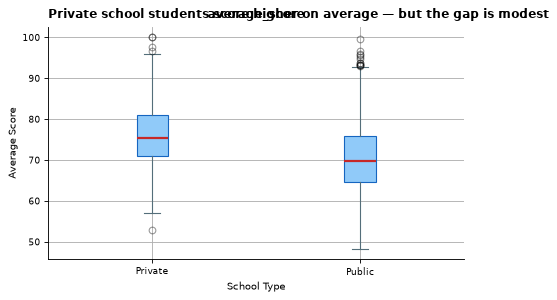

Saved → figures/school_boxplot.png


In [17]:
# ── Chart 3: Box plot of average_score by school type ─────────────────────────
fig, ax = plt.subplots(figsize=(6, 4))

df.boxplot(
    column="average_score", by="school_type",
    ax=ax, patch_artist=True,
    boxprops={"facecolor": "#90CAF9", "color": "#1565C0"},
    medianprops={"color": "#C62828", "linewidth": 2},
    whiskerprops={"color": "#546E7A"},
    capprops={"color": "#546E7A"},
    flierprops={"marker": "o", "color": "#546E7A", "alpha": 0.4}
)

ax.set_title(
    "Private school students score higher on average — but the gap is modest",
    loc="left", pad=8
)
ax.set_xlabel("School Type")
ax.set_ylabel("Average Score")
plt.suptitle("")   # remove pandas auto-title

plt.tight_layout()
plt.savefig("figures/school_boxplot.png", dpi=150, bbox_inches="tight")
plt.show()
print("Saved → figures/school_boxplot.png")

---
## 4 · Multivariate
**Goal:** Build pivot tables to test whether the school-type gap persists across attendance bands and study-hour quartiles.

In [18]:
# ── Attendance bands (quartile-based) ─────────────────────────────────────────
df["attendance_band"] = pd.qcut(
    df["attendance_rate"],
    q=4,
    labels=["Q1 Low", "Q2 Mid-Low", "Q3 Mid-High", "Q4 High"]
)

# ── Study-hour quartiles ───────────────────────────────────────────────────────
df["study_quartile"] = pd.qcut(
    df["study_hours"],
    q=4,
    labels=["Q1 Least", "Q2 Low", "Q3 High", "Q4 Most"]
)

print("Attendance bands created:")
print(df["attendance_band"].value_counts().sort_index().to_string())
print("\nStudy-hour quartiles created:")
print(df["study_quartile"].value_counts().sort_index().to_string())

Attendance bands created:
attendance_band
Q1 Low         308
Q2 Mid-Low     311
Q3 Mid-High    315
Q4 High        266

Study-hour quartiles created:
study_quartile
Q1 Least    311
Q2 Low      302
Q3 High     288
Q4 Most     299


In [19]:
# ── Pivot 1: School type × Attendance band → average_score ────────────────────
pivot_att = df.pivot_table(
    index="attendance_band",
    columns="school_type",
    values="average_score",
    aggfunc="mean"
).round(2)

pivot_att["Gap (Private − Public)"] = (pivot_att["Private"] - pivot_att["Public"]).round(2)

print("Pivot 1: Avg score by School Type × Attendance Band")
print("=" * 55)
print(pivot_att.to_string())

gap = pivot_att["Gap (Private − Public)"]
print(f"Interpretation: Private schools score higher in every attendance band (gap {gap.min():.1f}–{gap.max():.1f} points),")
print("so the overall gap is not just because private-school learners attend more.")
print("The data cannot say WHY the gap exists (resources, household income and school selection are all untested).")

Pivot 1: Avg score by School Type × Attendance Band
school_type      Private  Public  Gap (Private − Public)
attendance_band                                         
Q1 Low             72.14   65.96                    6.18
Q2 Mid-Low         75.74   69.13                    6.61
Q3 Mid-High        77.52   72.88                    4.64
Q4 High            79.39   74.19                    5.20
Interpretation: Private schools score higher in every attendance band (gap 4.6–6.6 points),
so the overall gap is not just because private-school learners attend more.
The data cannot say WHY the gap exists (resources, household income and school selection are all untested).


In [20]:
# ── Pivot 2: School type × Study-hour quartile → average_score ───────────────
pivot_study = df.pivot_table(
    index="study_quartile",
    columns="school_type",
    values="average_score",
    aggfunc="mean"
).round(2)

pivot_study["Gap (Private − Public)"] = (pivot_study["Private"] - pivot_study["Public"]).round(2)

print("Pivot 2: Avg score by School Type × Study-hour Quartile")
print("=" * 60)
print(pivot_study.to_string())

gap = pivot_study["Gap (Private − Public)"]
print(f"Interpretation: Private schools score higher in every study-hour quartile (gap {gap.min():.1f}–{gap.max():.1f} points),")
print("so the overall gap is not just because private-school learners study more. The cause is not identified by these data.")


Pivot 2: Avg score by School Type × Study-hour Quartile
school_type     Private  Public  Gap (Private − Public)
study_quartile                                         
Q1 Least          69.51   63.82                    5.69
Q2 Low            74.92   67.12                    7.80
Q3 High           76.18   71.18                    5.00
Q4 Most           83.65   80.06                    3.59
Interpretation: Private schools score higher in every study-hour quartile (gap 3.6–7.8 points),
so the overall gap is not just because private-school learners study more. The cause is not identified by these data.


### Who is At Risk?

In [21]:
# ── Pivot 3: Performance band × County — counts ───────────────────────────────
pivot_county_band = df.pivot_table(
    index="county",
    columns="performance_band",
    values="student_id",
    aggfunc="count",
    fill_value=0
)

print("Pivot 3: Student counts by County × Performance Band")
print("=" * 55)
print(pivot_county_band.to_string())

Pivot 3: Student counts by County × Performance Band
performance_band  At Risk  Meeting  Exceeding
county                                       
Kisumu                 17      105         86
Mombasa                19      115         78
Nairobi                17      102         65
Nakuru                 13      125         64
Nyeri                  18      111         74
Turkana                15      114         62


In [22]:
df["at_risk"] = df["performance_band"] == "At Risk"
total_risk = df["at_risk"].sum()

def risk_table(by):
    t = df.groupby(by, observed=True)["at_risk"].agg(n="size", at_risk="sum")
    t["pct_at_risk"] = (t["at_risk"] / t["n"] * 100).round(1)
    t["share_of_all_at_risk_%"] = (t["at_risk"] / total_risk * 100).round(1)
    return t

for by in ["study_quartile", "attendance_band", "school_type"]:
    print(f"\nAt Risk by {by}"); print(risk_table(by).to_string())

both = df[(df["study_quartile"] == "Q1 Least") & (df["attendance_band"] == "Q1 Low")]
pub  = df[(df["study_quartile"] == "Q1 Least") & (df["school_type"] == "Public")]
print(f"\nLowest study AND lowest attendance quartile: n = {len(both)}, "
      f"{both['at_risk'].mean()*100:.1f}% At Risk ({both['at_risk'].sum()} of {total_risk} At Risk learners)")
print(f"Public school AND lowest study quartile:      n = {len(pub)}, "
      f"{pub['at_risk'].mean()*100:.1f}% At Risk ({pub['at_risk'].sum()} of {total_risk} At Risk learners)")


At Risk by study_quartile
                  n  at_risk  pct_at_risk  share_of_all_at_risk_%
study_quartile                                                   
Q1 Least        311       66         21.2                    66.7
Q2 Low          302       24          7.9                    24.2
Q3 High         288        8          2.8                     8.1
Q4 Most         299        1          0.3                     1.0

At Risk by attendance_band
                   n  at_risk  pct_at_risk  share_of_all_at_risk_%
attendance_band                                                   
Q1 Low           308       64         20.8                    64.6
Q2 Mid-Low       311       22          7.1                    22.2
Q3 Mid-High      315        7          2.2                     7.1
Q4 High          266        6          2.3                     6.1

At Risk by school_type
               n  at_risk  pct_at_risk  share_of_all_at_risk_%
school_type                                                 

---
## 5 · Hypotheses
**Goal:** Fit a trend line of `average_score` against `study_hours`, report slope and R², and explain one limitation. Test the school-type gap formally.

In [23]:
# ── Trend line: average_score vs study_hours using np.polyfit ─────────────────
x = df["study_hours"].values
y = df["average_score"].values

# Degree-1 polynomial (linear trend)
slope, intercept = np.polyfit(x, y, 1)

# R² via scipy
r, p_value = stats.pearsonr(x, y)
r_squared = r ** 2

print("=" * 55)
print("Trend Line: average_score ~ study_hours")
print("=" * 55)
print(f"  Slope     : {slope:.4f}  points per hour of study")
print(f"  Intercept : {intercept:.4f}")
print(f"  R         : {r:.4f}")
print(f"  R²        : {r_squared:.4f}  ({r_squared*100:.1f}% of variance explained)")
print(f"  p-value   : {p_value:.4e}")
print()
print("Slope interpretation:")
print(f"  Each extra study hour is associated with a {slope:.2f}-point higher average score.")
print("  (Unit note: study_hours reaches 23.3, so 'per day' is impossible; we read it as hours per WEEK.)")
print()
print("Limitation:")
print(f"  R² = {r_squared:.2f}, so study hours explain only about half the variation in scores, and the line is fitted on")
print("  observational data, so it cannot show that adding study hours would raise a learner's score.")
print(f"  The line reaches the maximum score of 100 at about {(100-intercept)/slope:.0f} hours, so it must not be extrapolated beyond the data.")

Trend Line: average_score ~ study_hours
  Slope     : 2.1166  points per hour of study
  Intercept : 61.2596
  R         : 0.7039
  R²        : 0.4954  (49.5% of variance explained)
  p-value   : 3.6473e-180

Slope interpretation:
  Each extra study hour is associated with a 2.12-point higher average score.
  (Unit note: study_hours reaches 23.3, so 'per day' is impossible; we read it as hours per WEEK.)

Limitation:
  R² = 0.50, so study hours explain only about half the variation in scores, and the line is fitted on
  observational data, so it cannot show that adding study hours would raise a learner's score.
  The line reaches the maximum score of 100 at about 18 hours, so it must not be extrapolated beyond the data.


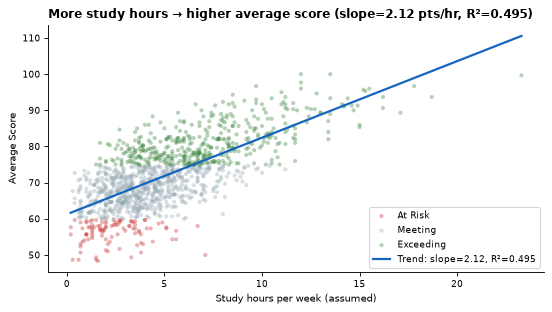

Saved → figures/trend_study_vs_score.png


In [24]:
# ── Scatter plot with trend line ──────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(7, 4))

# Colour points by performance band
band_colours = {"At Risk": "#C62828", "Meeting": "#90A4AE", "Exceeding": "#2E7D32"}
for band, colour in band_colours.items():
    mask = df["performance_band"] == band
    ax.scatter(
        df.loc[mask, "study_hours"],
        df.loc[mask, "average_score"],
        color=colour, alpha=0.35, s=14, label=band, edgecolors="none"
    )

# Trend line
x_line = np.linspace(x.min(), x.max(), 300)
y_line = slope * x_line + intercept
ax.plot(x_line, y_line, color="#1565C0", linewidth=2,
        label=f"Trend: slope={slope:.2f}, R²={r_squared:.3f}")

ax.set_title(
    f"More study hours → higher average score (slope={slope:.2f} pts/hr, R²={r_squared:.3f})",
    loc="left"
)
ax.set_xlabel("Study hours per week (assumed)")
ax.set_ylabel("Average Score")
ax.legend(fontsize=8, loc="lower right")

plt.tight_layout()
plt.savefig("figures/trend_study_vs_score.png", dpi=150, bbox_inches="tight")
plt.show()
print("Saved → figures/trend_study_vs_score.png")

In [25]:
# ── Hypothesis test: Does school type significantly affect average score? ──────
public_scores  = df[df["school_type"] == "Public"]["average_score"]
private_scores = df[df["school_type"] == "Private"]["average_score"]

t_stat, p_val = stats.ttest_ind(public_scores, private_scores, equal_var=False)

print("Independent samples t-test: Public vs Private school average scores")
print(f"  Public  mean = {public_scores.mean():.2f}  (n={len(public_scores)})")
print(f"  Private mean = {private_scores.mean():.2f}  (n={len(private_scores)})")
print(f"  Difference   = {private_scores.mean() - public_scores.mean():.2f} points")
print(f"  t-statistic  = {t_stat:.4f}")
print(f"  p-value      = {p_val:.4e}")
print()
if p_val < 0.05:
    print("Result: The difference IS statistically significant (p < 0.05).")
    print("Private school students score meaningfully higher on average.")
else:
    print("Result: The difference is NOT statistically significant (p ≥ 0.05).")

Independent samples t-test: Public vs Private school average scores
  Public  mean = 70.46  (n=866)
  Private mean = 76.01  (n=334)
  Difference   = 5.55 points
  t-statistic  = -10.2852
  p-value      = 3.9668e-23

Result: The difference IS statistically significant (p < 0.05).
Private school students score meaningfully higher on average.


Figures saved by this notebook: `figures/score_hist.png`, `figures/county_bar.png`, `figures/school_boxplot.png`, `figures/trend_study_vs_score.png`

## Findings

**Insight 1 — Study hours show the strongest link with scores.** Study hours correlate r = 0.70 with `average_score`; attendance is weaker (r = 0.36). Both are positive.

**Insight 2 — Trend line.** `np.polyfit` gives a slope of 2.12 points per extra study hour, R² = 0.495 (about half the variation in scores). *Unit note: study_hours reaches 23.3, so "per day" is impossible; we read it as hours per week.*

**Insight 3 — Private schools score about 5.6 points higher (76.0 vs 70.5).** The gap is statistically significant (Welch t = −10.3, p < 0.001) and holds in every attendance band (4.6–6.6 points) and study-hour quartile (3.6–7.8 points). It is smallest among the heaviest studiers. Public schools hold 94 of the 99 At Risk learners (95%); the data cannot say why.

**Insight 4 — Only 8.2% of learners are At Risk, and no county stands out.** Nairobi is highest (9.2%, 17 of 184) and Nakuru lowest (6.4%, 13 of 202), but the difference is not statistically significant (chi-square p = 0.92). County alone is a weak targeting basis.

**Insight 5 — Scores are roughly symmetric (mean 72.0, median 71.7, skew 0.26).** 56% of learners are Meeting, 36% Exceeding and 8% At Risk. 29 students (2.4%) are study-hour outliers (above 12.4 h); they do not drive the results.

## Recommendations

1. **Select learners by study time and attendance, not by county.** The lowest study-hour quartile holds 67% of all At Risk learners (21% of that group is At Risk, against 0.3% in the top quartile). Learners in both the lowest study and lowest attendance quartiles are 54% At Risk (38 of 71).
2. **Start with public-school learners in the lowest study-hour quartile** (227 learners, 27% At Risk, 61 of the 99 At Risk learners). Pilot with comparison schools before scaling, because these data show association, not what works.

## Limitations

All relationships are **associations, not causes**: study hours may reflect motivation, and the school-type gap may reflect household income or selection into private schools. The data are **synthetic**, have **no dates** (so the trend line is cross-sectional and not a forecast), and the linear fit ignores other factors and extreme values. Study hours is likely **self-reported** and its unit is unstated. County differences are within random variation.